In [3]:
import matplotlib.pyplot as plt
import numpy as np

from spectre import SPECTRE, SPECTREout, force_real, get_xinit_specwrap, plot_infaces

%load_ext autoreload
%autoreload 2
%matplotlib ipympl

np.set_printoptions(linewidth=170)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


W7-X fixed points example, based on the .h5 output file which has to be obtained from the .toml file

Rank 0: done volume 0
Rank 0: done volume 1
Poincare trace completed (3.94s)
find_axis for /home/balkovic/codes/spectre_outfromtoml/examples/analysis/finding_fixed_points/test_w7x.h5: 0 iterations
fp  message: The solution converged.
 success: True
  status: 1
     fun: [ 8.882e-16  9.541e-16]
       x: [-9.496e-01 -1.839e-07]
  method: hybr
    nfev: 40
    fjac: [[ 1.397e-01 -9.902e-01]
           [ 9.902e-01  1.397e-01]]
       r: [-5.416e-01 -4.332e-03  5.368e-03]
     qtf: [ 2.624e-13 -2.805e-14]
rax 5.949069  zax 0.000000  s -0.949567  th -0.000000
Magnetic axis r z s t:  5.949069117917928 3.644564065323074e-09 -0.9495670104517665 -1.8389290991926927e-07


/tmp/ipykernel_1041/695141112.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


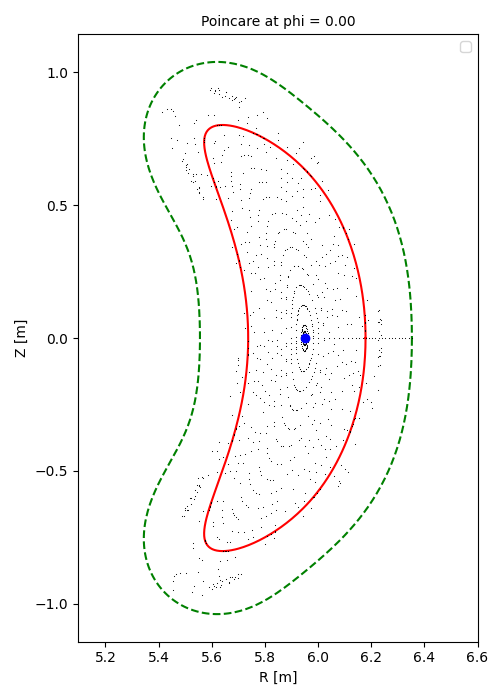

In [6]:

out = SPECTREout("test_w7x.h5")

init_pts = [
    np.array([[x, 0.0] for x in np.linspace(-0.99999, 1, 15)]) for _ in range(7)
]  # starting points for poincare section
out.trace_fieldlines(init_pts, num_threads=7, num_phi_planes=1, num_transits=50)  # run calculation

fig, ax = plt.subplots(figsize=(5, 7))
out.plot_infaces(ax=ax)
out.tracer.plot(ax=ax)

# Find the axis based on an initial guess which has been found to work directly without repeats.
r, z, s, t = out.find_axis(guess=[-0.989, 3.14], max_repeats=10, plot=False, verbose=True)
print("Magnetic axis r z s t: ", r, z, s, t)

ax.plot(r, z, "bo")

# # # Find the island fixed points. First try a bad guess, then it retries and finds a random point.
# # # Due to the hyperblic nature of x-points, this is very likely an o-point.
# r, z, s, t = out.find_island_fixed_point(vol=1, m=5, n=-5, guess=[0.5, 0 ], max_repeats=10, 
# plot=True, ax=ax)
# print("Island o-point r z s t: ", r, z, s, t)

# # start with a good guess, this will converge to the inboard x-point.
# r, z, s, t = out.find_island_fixed_point(vol=1, m=5, n=-5, guess=[-.5, np.pi], max_repeats=0, 
# plot=True, ax=ax)
# print("Island o-point r z s t: ", r, z, s, t)

plt.legend()
plt.tight_layout()

W7-X fixed points example, based on the .toml input file

readin :            : 
readin :     201.18 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  1 ; phiedge=  1.749725650650050E+00 ; curtor=  0.000000000000000E+00 ; curpol=  1.017876019628700E+02 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  5 ; Nvol=  1 ; Mvol=  2 ; Mpol= 12 ; Ntor= 12 
readin :            : pscale=  0.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-16,  16 
readin :            : Lrad = 14, 8,
readin :            : 
readin :     201.18 : Linitialize=  1 ;LautoinitBn=  0 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  4.000 ; epsilon=  1.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=  12 ; gBntol=  1.00000E-05 ; gBnbld=  6.66000E-01 
readin :    

/tmp/ipykernel_1041/1288527840.py:24: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


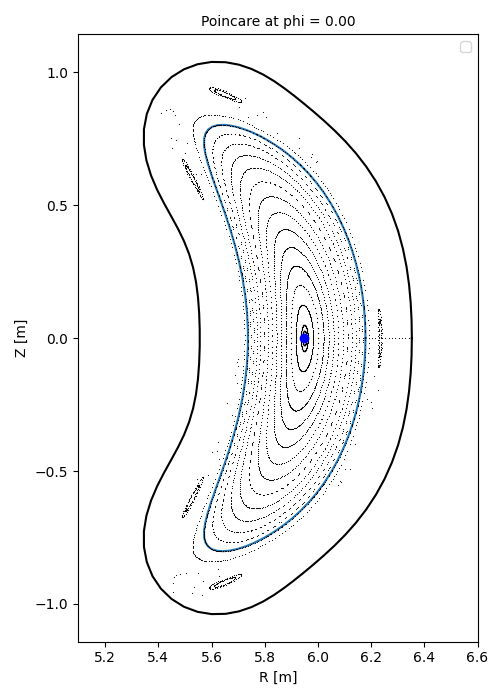

In [7]:

spectre = SPECTRE("test_w7x.toml")

xin = get_xinit_specwrap(spectre)  # get the interface modes for field calc and plotting

force_real(xin, spectre)  # force spectre to generate fields internally

out_spectre = spectre.create_spectreout()

init_pts = [np.array([[x, 0.0] for x in np.linspace(-0.99999, 1, 15)]) for _ in range(2)]
out_spectre.trace_fieldlines(
    init_pts, num_threads=7, num_phi_planes=1, num_transits=300
)  # run poincare calculation

fig, ax = plt.subplots(figsize=(5, 7))
plot_infaces(xin, spectre, ax=ax)
out_spectre.tracer.plot(ax=ax)

# Find the axis
r, z, s, t = out_spectre.find_axis(guess=[-0.949, 3.1], max_repeats=100)
print("Magnetic axis r z s t: ", r, z, s, t)

ax.plot(r, z, "bo")

plt.legend()
plt.tight_layout()

QA vacuum fixed points example, based on the .toml input file

readin :            : 
readin :     236.77 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.380000000000000E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  7 ; Mvol=  7 ; Mpol=  8 ; Ntor=  8 
readin :            : pscale=  0.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  3 ; mupf: tol,its=  1.00E-10, 128 
readin :            : Lrad = 10,10,10,10,10,10,10,
readin :            : 
readin :     236.77 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  4.000 ; epsilon=  1.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-0

/tmp/ipykernel_1041/4130379114.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


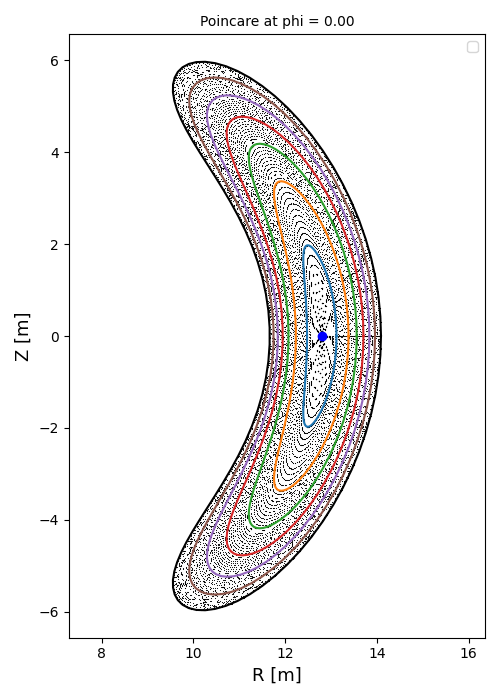

In [8]:
qa = SPECTRE("test_qa_nvol7.toml")

xin = get_xinit_specwrap(qa)

force_real(xin, qa)

out_qa = qa.create_spectreout()

init_pts = [np.array([[x, 0.0] for x in np.linspace(-1 + 1e-9, 1, 12)]) for _ in range(7)]
out_qa.trace_fieldlines(init_pts, num_threads=7, num_phi_planes=1, num_transits=200)  # run calc

fig, ax = plt.subplots(figsize=(5, 7))
out_qa.tracer.plot(ax=ax)
plot_infaces(xin, qa, ax=ax)
# out.plot_poincare(ax=ax)

# Find the axis
r, z, s, t = out_qa.find_axis(guess=[-0.999, 6.1], max_repeats=50)
print("Magnetic axis r z s t: ", r, z, s, t)

ax.plot(r, z, "bo")

plt.legend()
plt.tight_layout()